<img src="logo.png" alt="Vegeta" width="240">

# Kestrel — the test campaign: every CFD case, failures accepted

Notebook 38 designs Kestrel-4Q in a loop and plugs the CFD in where it exists; **this notebook is the CFD.** It
prepares and runs every Aeromant case the study asks for — Kestrel-4Q (Part I's airframe) and Kestrel-4Q-2 (elevons,
faired posts, no diagonals), each at its transition points with the four propellers as rotor disks, in the hover, and
bare from 0 to 90°; and the two finalist sections as extruded slabs — at the quality it is given, and writes what
solved to `designs/data/kestrel_cfd_results.json`, which notebook 38 reads on its next run (iteration 3, § 7).

**A failure is a result.** A case that fails in a step, or runs its iterations into nonsense, is listed as `FAILED` or
`diverged` with its reason, counted, and left out of the correction; nothing here raises on it. The first campaign
(screening, 400 iterations) solved the ten bare cases of Kestrel-4Q and lost all fourteen blown ones to the solver's
numerics — those numbers are in the results file now and this notebook is how they get replaced.

How to run it:

| variable | default | meaning |
|---|---|---|
| `VEGETA_SKIP_OPENFOAM=1` | unset | list and prepare only: every case NOT RUN (what this copy shows) |
| `KESTREL_CFD_QUALITY` | `screening` | `screening` (~0.3–0.5 M cells, 400 iterations) or `fine` (×3 cells, 800 iterations) |
| `KESTREL_CFD_JOBS` / `KESTREL_CFD_PROCESSORS` | 1 / 4 | cases in parallel / MPI ranks per case |
| `KESTREL_CFD_ONLY` | unset | `4Q-1`, `4Q-2`, `sections`, or a comma list: run those campaigns only |
| `KESTREL_CFD_SWEEP_ONLY=1` | unset | the bare sweeps only (no rotor disks): the cheap half |
| `KESTREL_FEA=0` | unset | skip the Talos (CalculiX) cases of the frame and the joint |

The cases are cached next to the notebook (`40_kestrel_tests.cache/`): a second run solves only what is new.
**Run notebook 41 (`prop_lab`) first**: its calibration of the 9×6 — the blade section the rotor disks are fed, the
drive tables, the propeller normal force — is read here and in notebook 38 when it is on file.

In [1]:
import json, math, os, shutil, sys, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vegeta import aeromant
sys.path.insert(0, "designs")
import kestrel, kestrel_systems as ks, kestrel_flight as kf, kestrel_transition as kt, kestrel_cfd as kcfd, kestrel_drawings as kd, kestrel_loop as kl, kestrel_fea as kfe

pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
RUNS = Path("_runs/kestrel_tests"); RUNS.mkdir(parents=True, exist_ok=True)
OUT = Path("output/40_kestrel_tests"); OUT.mkdir(parents=True, exist_ok=True)
RUN_CFD = os.environ.get("VEGETA_SKIP_OPENFOAM") != "1"
QUALITY = os.environ.get("KESTREL_CFD_QUALITY", "screening")
JOBS, PROCS = int(os.environ.get("KESTREL_CFD_JOBS", "1")), int(os.environ.get("KESTREL_CFD_PROCESSORS", "4"))
ONLY = [s.strip() for s in os.environ.get("KESTREL_CFD_ONLY", "4Q-1,4Q-2,sections").split(",") if s.strip()]
SWEEP_ONLY = os.environ.get("KESTREL_CFD_SWEEP_ONLY") == "1"
TODAY = datetime.date.today().isoformat()
print(f"CFD {'on' if RUN_CFD else 'NOT RUN (VEGETA_SKIP_OPENFOAM=1)'} | quality {QUALITY} ({kcfd.QUALITY[QUALITY]}) | jobs {JOBS} × {PROCS} ranks | campaigns {ONLY}"
      + (" | bare sweeps only" if SWEEP_ONLY else ""))
PL = ks.prop_lab_calibration()
print("prop_lab (notebook 41):", (f"calibration on file — cl x{PL['cl_scale']:.3f}, cd x{PL['cd_scale']:.3f}, CNα x{PL['cn_factor']:.3f}: the rotor disks' polar and the drive tables carry it"
                                  if PL["on_file"] else "NOT RUN: the rotor disks run on Boreas's generic blade section"))
try:
    import kestrel_section as ksec
    HAVE_ZEPHYR = True
except Exception as exc:
    HAVE_ZEPHYR = False; print("Zephyr not available:", type(exc).__name__)

CFD NOT RUN (VEGETA_SKIP_OPENFOAM=1) | quality screening ({'cells_per_length': 2.0, 'surface_level': 4, 'near_level': 3, 'wake_level': 2, 'iterations': 400, 'residual_target': 0.0001}) | jobs 1 × 4 ranks | campaigns ['4Q-1', '4Q-2', 'sections']
prop_lab (notebook 41): NOT RUN: the rotor disks run on Boreas's generic blade section


## 1. The aircraft and their transition points

The same vehicles as notebook 38: Kestrel-4Q from the default parameters, Kestrel-4Q-2 from the Part II options (the
CAD's wings are NACA 0012 in both — the reflexed section is the slabs' question, not the airframe's). The CFD points
come from each aircraft's nominal transitions: the first time the free-stream angle of attack passes 80, 60, 45, 30,
20, 15 and 10° going forward and coming back — 4Q-2's back transition entered at 13 m/s, its operating rule — plus
the **hover**, the level **cruise** at 16 m/s and the **stall** at 1.05 × the stall speed (the five states the
campaign is asked for: cruise, stall, hover, vertical → horizontal, horizontal → vertical), and the bare sweep at 10 m/s — thirteen angles, with 8, 12, 14 and 16° added to the design notebook's ten
so that the stall's peak is on the grid (the first campaign's 5° steps could not tell the model's CL max of 0.81 at
12° from the CFD's 0.54 at 15°).

In [2]:
P = kestrel.resolve(); A = kf.aero(P)
VEH = kt.make_vehicle(P, aero=A, name="Kestrel-4Q")
P2 = kestrel.resolve(dict(P, elevons=True, strut_fairing=True, bracing="posts"))
D2 = kf.drag_buildup(P2, faired=True)
VEH2 = kt.make_vehicle(P2, aero=A, pol=kf.polar(P2, a=A, d=D2), name="Kestrel-4Q-2")
NOM1 = [kt.simulate(VEH, "forward", t_tr=3.0), kt.simulate(VEH, "back", t_tr=3.0)]
NOM2 = [kt.simulate(VEH2, "forward", t_tr=3.0), kt.simulate(VEH2, "back", t_tr=3.0, V_entry=13.0)]
PTS = {"4Q-1": kcfd.points(NOM1, mass_kg=VEH.mass) + kcfd.flight_points(VEH), "4Q-2": kcfd.points(NOM2, mass_kg=VEH2.mass) + kcfd.flight_points(VEH2)}
VEHS = {"4Q-1": (VEH, P), "4Q-2": (VEH2, P2)}
for k, (v, p_) in VEHS.items():
    print(f"{k}: {v.mass:.3f} kg, CG {v.x_cg * 1000:.0f} mm, Cd0 {v.pol.cd0:.4f}, {len(PTS[k])} transition points")
display(pd.DataFrame({k: ep.metrics for k, ep in zip(("4Q-1 forward", "4Q-1 back", "4Q-2 forward", "4Q-2 back (13 m/s)"), NOM1 + NOM2)}).T[["height loss [m]", "height gain [m]", "pitch error max [deg]", "pass"]])

4Q-1: 1.686 kg, CG 215 mm, Cd0 0.0665, 16 transition points
4Q-2: 1.651 kg, CG 215 mm, Cd0 0.0234, 16 transition points


,height loss [m],height gain [m],pitch error max [deg],pass
4Q-1 forward,0.108397,0.389127,2.46243,True
4Q-1 back,0.563704,2.486073,4.654027,True
4Q-2 forward,0.137301,0.430777,2.493022,True
4Q-2 back (13 m/s),0.318484,1.756516,4.341757,True


## 2. The case list

Everything the campaign holds, with its template, air speed and rotor speeds, before a single solver starts. The
sections' slabs are the two finalists of notebook 38 § 14 (NACA 0012 and the reflexed NACA 23112 with k₂/k₁ 0.03)
at four angles, AR 8, 16 m/s.

In [3]:
SPECS = {k: kcfd.specs(PTS[k], sweep=True, sweep_alphas=kcfd.SWEEP_ALPHAS_FINE) for k in VEHS}      # the stall's peak resolved
if SWEEP_ONLY:
    SPECS = {k: {n: s for n, s in v.items() if not s["props"]} for k, v in SPECS.items()}
LISTS = {k: kcfd.not_run_table(v) for k, v in SPECS.items()}
for k, t in LISTS.items():
    print(f"{k}: {len(t)} cases ({int(t['template'].eq('aircraft_quad_rotor_disks').sum())} with rotor disks)"); display(t)
FINALISTS = [("NACA 0012", None), ("NACA 23112", 0.03)]
SSPEC = ksec.cfd_specs(FINALISTS) if HAVE_ZEPHYR else {}
SLIST = kcfd.section_not_run_table(SSPEC) if SSPEC else pd.DataFrame()
print(f"sections: {len(SLIST)} slab cases"); display(SLIST)
n_cases = sum(len(t) for t in LISTS.values()) + len(SLIST)
cells = {"screening": 0.4e6, "fine": 1.2e6}[QUALITY]
print(f"{n_cases} cases at {QUALITY}: ~{n_cases * cells / 1e6:.0f} M cells in all, {kcfd.QUALITY[QUALITY]['iterations']} iterations each — "
      f"order of {n_cases * (0.25 if QUALITY == 'screening' else 1.0) / JOBS:.0f} h on {PROCS} ranks per case")

4Q-1: 29 cases (16 with rotor disks)


,status,α [deg],V [m/s],source,rotor disks,template,rpm upper,rpm lower,Re (chord)
"forward 3 s: α 53°, 1.5 m/s, T 4.38/4.85 N",NOT RUN,52.894182,1.502634,forward 3 s,True,aircraft_quad_rotor_disks,6959.416668,7323.375427,14408.817654
"forward 3 s: α 45°, 2.1 m/s, T 4.47/5.02 N",NOT RUN,44.904703,2.100062,forward 3 s,True,aircraft_quad_rotor_disks,7069.55626,7488.626383,20137.576076
"forward 3 s: α 30°, 3.8 m/s, T 4.64/5.33 N",NOT RUN,29.973069,3.822928,forward 3 s,True,aircraft_quad_rotor_disks,7349.58457,7860.588523,36658.217085
"forward 3 s: α 20°, 5.8 m/s, T 4.58/5.36 N",NOT RUN,19.995271,5.808294,forward 3 s,True,aircraft_quad_rotor_disks,7546.298155,8109.622579,55695.971179
"forward 3 s: α 15°, 7.3 m/s, T 4.28/5.08 N",NOT RUN,14.997513,7.3228,forward 3 s,True,aircraft_quad_rotor_disks,7548.470859,8130.479978,70218.628002
"forward 3 s: α 10°, 9.3 m/s, T 3.10/3.94 N",NOT RUN,9.988898,9.285929,forward 3 s,True,aircraft_quad_rotor_disks,6965.549177,7631.274908,89043.15222
"back 3 s: α 80°, 6.0 m/s, T 0.27/1.66 N",NOT RUN,80.130305,6.032658,back 3 s,True,aircraft_quad_rotor_disks,1889.195452,4315.347784,57847.405862
"back 3 s: α 60°, 7.7 m/s, T 0.25/2.08 N",NOT RUN,60.038309,7.692476,back 3 s,True,aircraft_quad_rotor_disks,2378.065278,5106.871166,73763.470179
"back 3 s: α 45°, 9.9 m/s, T 0.25/2.45 N",NOT RUN,45.073565,9.943418,back 3 s,True,aircraft_quad_rotor_disks,3199.348591,5983.138945,95347.845625
"back 3 s: α 30°, 13.0 m/s, T 0.25/2.07 N",NOT RUN,30.020389,13.024933,back 3 s,True,aircraft_quad_rotor_disks,4478.501063,6526.059131,124896.61674


4Q-2: 29 cases (16 with rotor disks)


,status,α [deg],V [m/s],source,rotor disks,template,rpm upper,rpm lower,Re (chord)
"forward 3 s: α 53°, 1.5 m/s, T 4.20/4.65 N",NOT RUN,53.14645,1.502077,forward 3 s,True,aircraft_quad_rotor_disks,6816.082891,7168.507544,14403.478443
"forward 3 s: α 45°, 2.1 m/s, T 4.29/4.81 N",NOT RUN,44.965784,2.11808,forward 3 s,True,aircraft_quad_rotor_disks,6924.923031,7331.040384,20310.358692
"forward 3 s: α 30°, 3.9 m/s, T 4.42/5.08 N",NOT RUN,29.961108,3.879652,forward 3 s,True,aircraft_quad_rotor_disks,7192.76776,7684.763465,37202.143778
"forward 3 s: α 20°, 5.9 m/s, T 4.31/5.05 N",NOT RUN,19.987243,5.896848,forward 3 s,True,aircraft_quad_rotor_disks,7355.55551,7901.371568,56545.119648
"forward 3 s: α 15°, 7.4 m/s, T 3.95/4.70 N",NOT RUN,14.963228,7.429636,forward 3 s,True,aircraft_quad_rotor_disks,7306.101362,7875.094081,71243.080415
"forward 3 s: α 10°, 9.4 m/s, T 2.75/3.54 N",NOT RUN,9.984977,9.39752,forward 3 s,True,aircraft_quad_rotor_disks,6684.32229,7342.825724,90113.205116
"back 3 s: α 80°, 6.1 m/s, T 0.34/1.69 N",NOT RUN,80.180564,6.144409,back 3 s,True,aircraft_quad_rotor_disks,2000.503379,4352.54203,58918.992735
"back 3 s: α 60°, 7.8 m/s, T 0.25/2.01 N",NOT RUN,60.124531,7.792917,back 3 s,True,aircraft_quad_rotor_disks,2387.249901,5033.615323,74726.596957
"back 3 s: α 45°, 10.0 m/s, T 0.25/2.34 N",NOT RUN,45.060295,10.031351,back 3 s,True,aircraft_quad_rotor_disks,3217.323032,5886.761416,96191.036581
"back 3 s: α 30°, 12.9 m/s, T 0.25/1.93 N",NOT RUN,30.035807,12.895433,back 3 s,True,aircraft_quad_rotor_disks,4442.675577,6368.223999,123654.841676


sections: 8 slab cases


,status,α [deg],V [m/s],Re (chord),AR,template,reads against
"NACA 0012, α 0°, 16 m/s, AR 8 slab",NOT RUN,0.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 4°, 16 m/s, AR 8 slab",NOT RUN,4.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 8°, 16 m/s, AR 8 slab",NOT RUN,8.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 12°, 16 m/s, AR 8 slab",NOT RUN,12.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 0°, 16 m/s, AR 8 slab",NOT RUN,0.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 4°, 16 m/s, AR 8 slab",NOT RUN,4.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 8°, 16 m/s, AR 8 slab",NOT RUN,8.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 12°, 16 m/s, AR 8 slab",NOT RUN,12.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's


66 cases at screening: ~26 M cells in all, 400 iterations each — order of 16 h on 4 ranks per case


## 3. The campaigns

One function runs a campaign: plan the cases (the STL of the airframe at each angle, the four disks at Boreas's rpm),
run them through the cache, build the table — `solved`, `diverged`, `FAILED` or `NOT RUN` per case — print the
summary and write the solved cases into the results file under the campaign's key. A campaign that solved nothing
leaves the previous record for that key alone.

In [4]:
def campaign(key, veh, p_, spec):
    T = kcfd.not_run_table(spec)
    if RUN_CFD and key in ONLY:
        try:
            cases = kcfd.plan(RUNS / key, PTS[key], x_cg_m=veh.x_cg, z_cg_m=veh.z_cg, quality=QUALITY, sweep=True, p=p_, sweep_alphas=kcfd.SWEEP_ALPHAS_FINE)
            cases = {n: c for n, c in cases.items() if n in spec}
            names = list(cases)
            res = aeromant.run_cases([cases[n] for n in names], jobs=JOBS, processors=PROCS, progress=True, cache=True)
            T = kcfd.table(dict(zip(names, res)), spec, p_)
        except Exception as exc:                        # no OpenFOAM, no CAD kernel, a broken environment: the list stays NOT RUN
            print(f"{key}: CFD not run — {type(exc).__name__}: {str(exc)[:200]}")
    sm = kcfd.summary(T)
    print(f"{key}: {sm['line']}")
    kcfd.save_records(T, kcfd.RESULTS_JSON, key=key, meta={"source": "40_kestrel_tests", "quality": QUALITY, "aircraft": veh.name, "date": TODAY,
                                                           "iterations": kcfd.QUALITY[QUALITY]["iterations"]})
    T.to_csv(OUT / f"cfd_{key}.csv")
    return T
TABLES = {}
TABLES["4Q-1"] = campaign("4Q-1", VEH, P, SPECS["4Q-1"]); display(TABLES["4Q-1"])

4Q-1: 0 of 29 cases solved (0 of 16 with rotor disks, 0 bare), 0 diverged, 0 failed, 29 not run


,status,α [deg],V [m/s],source,rotor disks,template,rpm upper,rpm lower,Re (chord)
"forward 3 s: α 53°, 1.5 m/s, T 4.38/4.85 N",NOT RUN,52.894182,1.502634,forward 3 s,True,aircraft_quad_rotor_disks,6959.416668,7323.375427,14408.817654
"forward 3 s: α 45°, 2.1 m/s, T 4.47/5.02 N",NOT RUN,44.904703,2.100062,forward 3 s,True,aircraft_quad_rotor_disks,7069.55626,7488.626383,20137.576076
"forward 3 s: α 30°, 3.8 m/s, T 4.64/5.33 N",NOT RUN,29.973069,3.822928,forward 3 s,True,aircraft_quad_rotor_disks,7349.58457,7860.588523,36658.217085
"forward 3 s: α 20°, 5.8 m/s, T 4.58/5.36 N",NOT RUN,19.995271,5.808294,forward 3 s,True,aircraft_quad_rotor_disks,7546.298155,8109.622579,55695.971179
"forward 3 s: α 15°, 7.3 m/s, T 4.28/5.08 N",NOT RUN,14.997513,7.3228,forward 3 s,True,aircraft_quad_rotor_disks,7548.470859,8130.479978,70218.628002
"forward 3 s: α 10°, 9.3 m/s, T 3.10/3.94 N",NOT RUN,9.988898,9.285929,forward 3 s,True,aircraft_quad_rotor_disks,6965.549177,7631.274908,89043.15222
"back 3 s: α 80°, 6.0 m/s, T 0.27/1.66 N",NOT RUN,80.130305,6.032658,back 3 s,True,aircraft_quad_rotor_disks,1889.195452,4315.347784,57847.405862
"back 3 s: α 60°, 7.7 m/s, T 0.25/2.08 N",NOT RUN,60.038309,7.692476,back 3 s,True,aircraft_quad_rotor_disks,2378.065278,5106.871166,73763.470179
"back 3 s: α 45°, 9.9 m/s, T 0.25/2.45 N",NOT RUN,45.073565,9.943418,back 3 s,True,aircraft_quad_rotor_disks,3199.348591,5983.138945,95347.845625
"back 3 s: α 30°, 13.0 m/s, T 0.25/2.07 N",NOT RUN,30.020389,13.024933,back 3 s,True,aircraft_quad_rotor_disks,4478.501063,6526.059131,124896.61674


In [5]:
TABLES["4Q-2"] = campaign("4Q-2", VEH2, P2, SPECS["4Q-2"]); display(TABLES["4Q-2"])

4Q-2: 0 of 29 cases solved (0 of 16 with rotor disks, 0 bare), 0 diverged, 0 failed, 29 not run


,status,α [deg],V [m/s],source,rotor disks,template,rpm upper,rpm lower,Re (chord)
"forward 3 s: α 53°, 1.5 m/s, T 4.20/4.65 N",NOT RUN,53.14645,1.502077,forward 3 s,True,aircraft_quad_rotor_disks,6816.082891,7168.507544,14403.478443
"forward 3 s: α 45°, 2.1 m/s, T 4.29/4.81 N",NOT RUN,44.965784,2.11808,forward 3 s,True,aircraft_quad_rotor_disks,6924.923031,7331.040384,20310.358692
"forward 3 s: α 30°, 3.9 m/s, T 4.42/5.08 N",NOT RUN,29.961108,3.879652,forward 3 s,True,aircraft_quad_rotor_disks,7192.76776,7684.763465,37202.143778
"forward 3 s: α 20°, 5.9 m/s, T 4.31/5.05 N",NOT RUN,19.987243,5.896848,forward 3 s,True,aircraft_quad_rotor_disks,7355.55551,7901.371568,56545.119648
"forward 3 s: α 15°, 7.4 m/s, T 3.95/4.70 N",NOT RUN,14.963228,7.429636,forward 3 s,True,aircraft_quad_rotor_disks,7306.101362,7875.094081,71243.080415
"forward 3 s: α 10°, 9.4 m/s, T 2.75/3.54 N",NOT RUN,9.984977,9.39752,forward 3 s,True,aircraft_quad_rotor_disks,6684.32229,7342.825724,90113.205116
"back 3 s: α 80°, 6.1 m/s, T 0.34/1.69 N",NOT RUN,80.180564,6.144409,back 3 s,True,aircraft_quad_rotor_disks,2000.503379,4352.54203,58918.992735
"back 3 s: α 60°, 7.8 m/s, T 0.25/2.01 N",NOT RUN,60.124531,7.792917,back 3 s,True,aircraft_quad_rotor_disks,2387.249901,5033.615323,74726.596957
"back 3 s: α 45°, 10.0 m/s, T 0.25/2.34 N",NOT RUN,45.060295,10.031351,back 3 s,True,aircraft_quad_rotor_disks,3217.323032,5886.761416,96191.036581
"back 3 s: α 30°, 12.9 m/s, T 0.25/1.93 N",NOT RUN,30.035807,12.895433,back 3 s,True,aircraft_quad_rotor_disks,4442.675577,6368.223999,123654.841676


In [6]:
STAB = SLIST
if SSPEC and RUN_CFD and "sections" in ONLY:
    try:
        scases = {k: kcfd.section_case(RUNS / "sections", v, quality=QUALITY) for k, v in SSPEC.items()}
        names = list(scases)
        res = aeromant.run_cases([scases[n] for n in names], jobs=JOBS, processors=PROCS, progress=True, cache=True)
        STAB = kcfd.section_table(dict(zip(names, res)), SSPEC)
    except Exception as exc:
        print(f"sections: CFD not run — {type(exc).__name__}: {str(exc)[:200]}")
if len(STAB):
    st = STAB["status"].astype(str)
    print("sections:", ", ".join(f"{int((st == k).sum())} {k}" for k in ("solved", "diverged", "FAILED", "NOT RUN")))
    kcfd.save_section_table(STAB, kcfd.RESULTS_JSON, key="sections", meta={"source": "40_kestrel_tests", "quality": QUALITY, "date": TODAY})
    STAB.to_csv(OUT / "cfd_sections.csv")
    display(STAB)
    if HAVE_ZEPHYR and "cl section estimate" in STAB.columns:                       # the slab against NeuralFoil
        ST_ = ksec.table()
        rows = {}
        for k, r in STAB[STAB["status"] == "solved"].iterrows():
            sec = [c for c in FINALISTS if r["section"].startswith(c[0]) and ((c[1] is None) == ("k₂" not in r["section"]))]
            if sec:
                pc = ST_[ksec.key(*sec[0])]["polar_cruise"]
                rows[k] = {"α [deg]": r["α [deg]"], "cl slab → section": r["cl section estimate"], "cl NeuralFoil": float(np.interp(r["α [deg]"], pc["alpha_deg"], pc["cl"])),
                           "cd slab (3-D)": r["CD"], "cd NeuralFoil (2-D)": float(np.interp(r["α [deg]"], pc["alpha_deg"], pc["cd"])), "Cm slab": r["Cm (c/4, chord)"],
                           "cm NeuralFoil": float(np.interp(r["α [deg]"], pc["alpha_deg"], pc["cm"]))}
        if rows:
            display(pd.DataFrame(rows).T.round(4))

sections: 0 solved, 0 diverged, 0 FAILED, 8 NOT RUN


,status,α [deg],V [m/s],Re (chord),AR,template,reads against
"NACA 0012, α 0°, 16 m/s, AR 8 slab",NOT RUN,0.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 4°, 16 m/s, AR 8 slab",NOT RUN,4.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 8°, 16 m/s, AR 8 slab",NOT RUN,8.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 12°, 16 m/s, AR 8 slab",NOT RUN,12.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 0°, 16 m/s, AR 8 slab",NOT RUN,0.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 4°, 16 m/s, AR 8 slab",NOT RUN,4.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 8°, 16 m/s, AR 8 slab",NOT RUN,8.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 12°, 16 m/s, AR 8 slab",NOT RUN,12.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's


## 3b. The structure in Talos

The carbon frame as solid tubes for the X-braced and the posts-only truss (A the 4 g pull-up, B the 75 % wing, C the
heading manoeuvre's torsion, the modes with the motor units) and the printed spar–post joint — `kestrel_fea`, the
same cases notebook 38 § 8b prepares — solved here when CalculiX is installed (`KESTREL_FEA=0` skips them). The
table is the result whatever the solver did; it is written to `designs/data/kestrel_fea_results.json`.

In [7]:
RUN_FEA = (bool(shutil.which("ccx")) and os.environ.get("KESTREL_FEA", "1") != "0")
FEA = kfe.cases(RUNS / "fea", P, mass_kg=VEH.mass, bracings=("x", "posts"))
FEA_RES = kfe.solve(FEA, RUNS / "fea", run=RUN_FEA, threads=PROCS, progress=RUN_FEA)
FEAT = kfe.table(FEA, FEA_RES)
print(kfe.summary(FEAT)["line"] + ("" if RUN_FEA else " — CalculiX not installed or KESTREL_FEA=0"))
display(FEAT)
FEAT.to_csv(OUT / "fea_cases.csv")
kfe.save(FEAT, kcfd.RESULTS_JSON.parent / "kestrel_fea_results.json", meta={"source": "40_kestrel_tests", "date": TODAY, "mass_kg": VEH.mass})
REF = kfe.plane_frame_reference(P, mass_kg=VEH.mass)
display(REF.astype({c: float for c in REF.columns if c not in ("bracing", "case")}).round(2))

0 of 9 FEA cases solved, 0 failed, 9 not run — CalculiX not installed or KESTREL_FEA=0


,part,bracing,kind,status,description,note
frame_x_A,frame,x,static,NOT RUN,"4 g pull-up, the lift elliptic on both wings, the motors' and wings' inertia...",NOT RUN: frame_x_A in _runs/kestrel_tests/fea/frame_x_A (run=False)
frame_x_B,frame,x,static,NOT RUN,4 g with the upper wing carrying 75 % (one wing stalling first) (ultimate ×1.5),NOT RUN: frame_x_B in _runs/kestrel_tests/fea/frame_x_B (run=False)
frame_x_C,frame,x,static,NOT RUN,"the heading manoeuvre in the hover: M1 and M4 at 12.0 N, M2 and M3 at 0.25 N...",NOT RUN: frame_x_C in _runs/kestrel_tests/fea/frame_x_C (run=False)
frame_x_modes,frame,x,modes,NOT RUN,the first modes with the motor units as point masses at the stations,
frame_posts_A,frame,posts,static,NOT RUN,"4 g pull-up, the lift elliptic on both wings, the motors' and wings' inertia...",NOT RUN: frame_posts_A in _runs/kestrel_tests/fea/frame_posts_A (run=False)
frame_posts_B,frame,posts,static,NOT RUN,4 g with the upper wing carrying 75 % (one wing stalling first) (ultimate ×1.5),NOT RUN: frame_posts_B in _runs/kestrel_tests/fea/frame_posts_B (run=False)
frame_posts_C,frame,posts,static,NOT RUN,"the heading manoeuvre in the hover: M1 and M4 at 12.0 N, M2 and M3 at 0.25 N...",NOT RUN: frame_posts_C in _runs/kestrel_tests/fea/frame_posts_C (run=False)
frame_posts_modes,frame,posts,modes,NOT RUN,the first modes with the motor units as point masses at the stations,
joint_post,joint,,static,NOT RUN,"the post's 5.5 N (ultimate) into the printed socket, the spar bore held; bui...",NOT RUN: joint_post in _runs/kestrel_tests/fea/joint_post (run=False)


,bracing,case,"spar stress, limit [MPa]","spar stress, ultimate [MPa]","tip deflection, upper, limit [mm]","tip deflection, ultimate [mm]",spar reserve (limit),"first mode, symmetric [Hz]","first mode, antisymmetric [Hz]"
frame_x_A,x,A,11.50,17.26,-0.09,-0.14,34.77,NaN,NaN
frame_x_B,x,B,12.66,18.99,-0.15,-0.22,31.60,NaN,NaN
frame_x_modes,x,modes,NaN,NaN,NaN,NaN,NaN,260.53,1640.06
frame_posts_A,posts,A,21.62,32.44,1.98,2.97,18.50,NaN,NaN
frame_posts_B,posts,B,27.27,40.90,1.91,2.86,14.67,NaN,NaN
frame_posts_modes,posts,modes,NaN,NaN,NaN,NaN,NaN,15.61,1615.61
frame_none_A,none,A,21.62,32.44,1.98,2.97,18.50,NaN,NaN
frame_none_B,none,B,52.05,78.08,6.38,9.57,7.68,NaN,NaN
frame_none_modes,none,modes,NaN,NaN,NaN,NaN,NaN,15.61,15.61


## 4. Plug in and fly again

What notebook 38 does with the results, done here first so the campaign reads its own answer: for each aircraft the
bare sweep against the model's polar (lift slope, CL max, Cd0, the static margin from Cmα), the correction — from the
blown cases if any solved, in α and the slipstream ratio μ; else from the sweep, in α — and the transition matrix flown
on it beside the model's.


===== 4Q-1
campaign: {'source': '38_kestrel run on an OpenFOAM machine (uploaded notebook), Part I points, screening quality, 400 iterations', 'aircraft': 'Kestrel-4Q (round struts, NACA 0012, no elevons in the CAD)', 'quality': 'screening', 'date': '2026-10-16'}


,solved,diverged,FAILED,NOT RUN,n,solved with rotor disks,solved bare,with rotor disks
cases,10,2,12,0,24,0,10,14


,α [deg],CL CFD,CL model,ΔCL,CD CFD,CD model,ΔCD,Cm CFD,Cm model,ΔCm,converged
"bare airframe, α 0°, 10 m/s",0.0,-0.048798,0.0,-0.048798,0.053229,0.066549,-0.01332,0.02103,0.002131,0.018899,False
"bare airframe, α 5°, 10 m/s",5.0,0.319246,0.352045,-0.032799,0.08082,0.075034,0.005786,-0.030379,-0.049811,0.019432,False
"bare airframe, α 10°, 10 m/s",10.0,0.507562,0.5645,-0.056938,0.134349,0.101314,0.033035,-0.07048,-0.084367,0.013887,False
"bare airframe, α 15°, 10 m/s",15.0,0.541091,0.379896,0.161195,0.197516,0.151589,0.045927,-0.088153,-0.074912,-0.013241,False
"bare airframe, α 20°, 10 m/s",20.0,0.571487,0.42127,0.150217,0.296818,0.218724,0.078094,-0.132917,-0.100202,-0.032715,False
"bare airframe, α 30°, 10 m/s",30.0,0.571837,0.576299,-0.004462,0.45992,0.399271,0.060649,-0.120245,-0.172552,0.052307,False
"bare airframe, α 45°, 10 m/s",45.0,0.614804,0.684567,-0.069763,0.752433,0.751116,0.001317,-0.203169,-0.292263,0.089094,False
"bare airframe, α 60°, 10 m/s",60.0,0.449682,0.605558,-0.155876,0.935665,1.115406,-0.179741,-0.241783,-0.403025,0.161242,False
"bare airframe, α 75°, 10 m/s",75.0,0.207578,0.354231,-0.146653,0.856935,1.388556,-0.531621,-0.21171,-0.481212,0.269502,False
"bare airframe, α 90°, 10 m/s",90.0,0.060415,0.0,0.060415,0.767666,1.489763,-0.722097,-0.229449,-0.509726,0.280277,False


,CFD,model
CLα [1/rad],3.188,3.234
CL max,0.615,0.685
α at CL max [deg],45.000,45.000
CL max below 20°,0.541,0.564
α of it [deg],15.000,10.000
CD at the lowest α,0.053,0.067
Cmα [1/rad],-0.524,-0.496
static margin from Cmα [chords],0.164,0.153


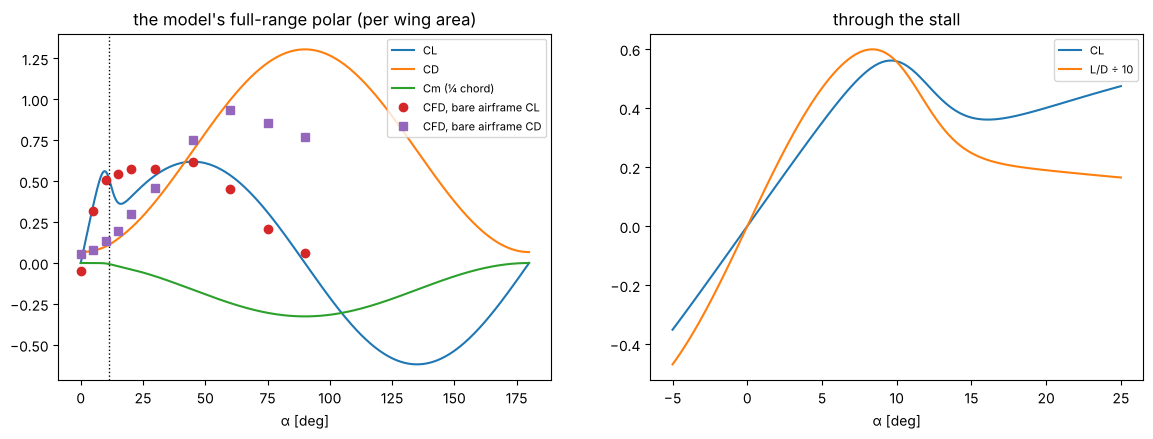

correction from the sweep, 10 points


height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  moment shortfall [s]  roll demand / authority  pass
vehicle     direction t_tr [s] headwind [m/s]                                                                                                                                             
model       forward   3.0      0.0                        0.11             0.39                   2.46                           0.95                   0.0                     0.07  True
                               6.0                        0.45             0.09                   1.91                           2.50                   0.0                     0.05  True
                      5.0      0.0                        1.12             0.37                   1.55                           2.55                   0.0                     0.07  True
                               6.0                        1.44             0.43                   1.31                           4.47                   0.0                     0.07  True
            back      3.0      0.0                        0.56             2.49                   4.65                           1.50                   0.0                     0.28  True
                               6.0                        0.18             2.49                   4.65                           1.50                   0.0                     0.28  True
                      5.0      0.0                        0.93             3.40                   2.35                           1.84                   0.0                     0.23  True
                               6.0                        0.46             3.40                   2.35                           1.84                   0.0                     0.23  True
CFD (sweep) forward   3.0      0.0                        0.16             0.42                   2.25                           0.93                   0.0                     0.07  True
                               6.0                        0.30             0.09                   2.27                           2.38                   0.0                     0.07  True
                      5.0      0.0                        0.60             0.36                   2.12                           2.38                   0.0                     0.07  True
                               6.0                        0.71             0.17                   1.45                           4.27                   0.0                     0.07  True
            back      3.0      0.0                        0.30             1.31                   3.31                           1.41                   0.0                     0.38  True
                               6.0                        0.21             1.31                   3.31                           1.41                   0.0                     0.38  True
                      5.0      0.0                        0.26             1.34                   1.92                           2.12                   0.0                     0.30  True
                               6.0                        0.24             1.34                   1.92                           2.12                   0.0                     0.30  True

CFD (sweep): 8 of 8 pass
model: 8 of 8 pass

===== 4Q-2
campaign: {'source': '40_kestrel_tests', 'quality': 'screening', 'aircraft': 'Kestrel-4Q-2', 'date': '2026-10-16', 'iterations': 400}


,solved,diverged,FAILED,NOT RUN,n,solved with rotor disks,solved bare,with rotor disks
cases,0,0,0,29,29,0,0,16


nothing usable solved: the transitions stand on the model


In [8]:
VERDICTS = {}
for key, (veh, p_) in VEHS.items():
    print(f"\n===== {key}")
    PI = kcfd.plug_in(veh, kcfd.RESULTS_JSON, key)
    camp = PI["campaign"]
    if not camp:
        print("no campaign on file"); continue
    print("campaign:", camp.get("meta")); display(pd.Series(camp["summary"], name="cases").to_frame().T)
    RT = kcfd.records_table(camp["records"]) if camp["records"] else None
    if RT is not None:
        cmp = kcfd.sweep_comparison(RT, veh)
        if len(cmp):
            display(cmp.drop(columns=["note"]).astype({"α [deg]": float}).round(3)); display(pd.DataFrame(kcfd.sweep_numbers(cmp)).round(3))
            kd.polar_figure(veh.pol, RT); plt.show()
    if PI["airframe"] is None:
        print("nothing usable solved: the transitions stand on the model"); continue
    corr = PI["airframe"]
    print(f"correction from the {corr.source}, {len(corr.samples)} points")
    vc = kt.make_vehicle(p_, aero=A, pol=veh.pol, airframe=corr, name=f"{veh.name}, CFD aero")
    kw = {"V_entry": 13.0} if key == "4Q-2" else {}
    mats = {}
    for lab, v_ in (("model", veh), (f"CFD ({corr.source})", vc)):
        m_, _ = kt.matrix({lab: v_}, durations=(3.0, 5.0), headwinds=(0.0, 6.0), kinds=("forward",), progress=False)
        mb, _ = kt.matrix({lab: v_}, durations=(3.0, 5.0), headwinds=(0.0, 6.0), kinds=("back",), progress=False, **kw)
        mats[lab] = pd.concat([m_, mb])
    MATK = pd.concat(mats.values())
    cols = ["height loss [m]", "height gain [m]", "pitch error max [deg]", "time stalled, free stream [s]", "moment shortfall [s]", "roll demand / authority", "pass"]
    display(MATK[cols].astype({c: float for c in cols if c != "pass"}).round(2))
    VERDICTS[key] = kt.verdict(MATK)
    for k, v in VERDICTS[key].items():
        print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
    MATK.to_csv(OUT / f"transitions_{key}.csv")

## 5. The campaign's record

What is on file for notebook 38 to read, campaign by campaign, and every case that did not solve with its reason —
the list to work through before the next run.

In [9]:
DOC = kcfd.load_records(kcfd.RESULTS_JSON) or {"campaigns": {}}
REC = pd.DataFrame({k: dict(v.get("summary", {}), **{"source": v.get("meta", {}).get("source"), "quality": v.get("meta", {}).get("quality"), "date": v.get("meta", {}).get("date")})
                    for k, v in DOC["campaigns"].items()}).T
display(REC)
FAILS = {f"{k}: {n}": s for k, v in DOC["campaigns"].items() for n, s in v.get("statuses", {}).items() if s["status"] in ("FAILED", "diverged")}
if FAILS:
    print(f"{len(FAILS)} cases did not solve:"); display(pd.DataFrame(FAILS).T)
else:
    print("every case that ran solved" if any(v.get("summary", {}).get("solved") for v in DOC["campaigns"].values()) else "nothing has run yet")
CHK = [kl.check("campaigns on file", len(DOC["campaigns"]), "≥", 3),
       kl.check("FEA cases solved (Talos)", kfe.summary(FEAT)["solved"], "≥", len(FEAT)),
       kl.check("4Q-1: blown cases solved", DOC["campaigns"].get("4Q-1", {}).get("summary", {}).get("solved with rotor disks", 0), "≥", 1),
       kl.check("4Q-1: bare sweep solved", DOC["campaigns"].get("4Q-1", {}).get("summary", {}).get("solved bare", 0), "≥", 10),
       kl.check("4Q-2: blown cases solved", DOC["campaigns"].get("4Q-2", {}).get("summary", {}).get("solved with rotor disks", 0), "≥", 1),
       kl.check("4Q-2: bare sweep solved", DOC["campaigns"].get("4Q-2", {}).get("summary", {}).get("solved bare", 0), "≥", 10),
       kl.check("sections: slabs solved", DOC["campaigns"].get("sections", {}).get("summary", {}).get("solved", 0), "≥", 8)]
display(kl.check_table(CHK, "the campaign"))
print("the file:", kcfd.RESULTS_JSON, "— notebook 38 reads it on its next run (§ 7, iteration 3).")

# ---- the design dossier: every number of this notebook as Markdown to paste into a conversation (kestrel_report)
import kestrel_report as kr
def _g(n):
    return globals().get(n)
def _chk(names):
    import pandas as pd
    out = {}
    for n in names:
        c = _g(n)
        if c:
            out[n] = kl.check_table(c, n)
    return out

REPORT = {"settings": {"CFD": "on" if RUN_CFD else "NOT RUN", "quality": QUALITY, "jobs": JOBS, "processors": PROCS, "campaigns": ", ".join(ONLY), "sweep only": SWEEP_ONLY, "FEA": "on" if RUN_FEA else "NOT RUN"},
          "aircraft": pd.DataFrame({k: {"mass [kg]": v.mass, "CG [mm]": v.x_cg * 1000, "Cd0": v.pol.cd0, "transition points": len(PTS[k])} for k, (v, _) in VEHS.items()}).T,
          "prop_lab calibration": PL, "case lists": {k: t[[c for c in ("status", "α [deg]", "V [m/s]", "template", "source") if c in t.columns]] for k, t in LISTS.items()},
          "section slabs": SLIST, "campaign tables": {k: t for k, t in TABLES.items()}, "slab results": _g("STAB"), "FEA (Talos)": FEAT, "plane-frame reference": REF,
          "verdicts, model against CFD": VERDICTS, "campaigns on file": REC, "cases that did not solve": pd.DataFrame(FAILS).T if FAILS else "none", "checks": kl.check_table(CHK, "the campaign")}
EXP = kr.export("40_kestrel_tests", "Kestrel — notebook 40, the CFD and FEA campaign", REPORT, meta={"date": TODAY, "quality": QUALITY})
print("JSON report:", EXP["json"], f"({EXP['json_kB']} kB) | JSON dossier:", EXP["dossier_json"], f"({EXP['dossier_json_kB']} kB) | Markdown:", EXP["markdown"])
kr.paste("40_kestrel_tests", max_lines=30)

,solved,diverged,FAILED,NOT RUN,n,solved with rotor disks,solved bare,with rotor disks,source,quality,date
4Q-1,10,2,12,0,24,0,10,14,"38_kestrel run on an OpenFOAM machine (uploaded notebook), Part I points, sc...",screening,2026-10-16
4Q-2,0,0,0,29,29,0,0,16,40_kestrel_tests,screening,2026-10-16
sections,0,0,0,8,NaN,NaN,NaN,NaN,40_kestrel_tests,screening,2026-10-16


14 cases did not solve:


,status,note,rotor disks,α [deg],V [m/s]
"4Q-1: forward 3 s: α 53°, 1.5 m/s, T 4.63/4.64 N",diverged,diverged: |coefficients| beyond 1e90,True,52.8861,1.50599
"4Q-1: forward 3 s: α 45°, 2.1 m/s, T 4.73/4.80 N",FAILED,step solver failed (log not in the notebook),True,44.998494,2.095608
"4Q-1: forward 3 s: α 30°, 3.8 m/s, T 4.91/5.11 N",FAILED,step solver failed (log not in the notebook),True,29.934512,3.832142
"4Q-1: forward 3 s: α 20°, 5.8 m/s, T 4.85/5.14 N",diverged,diverged: |coefficients| beyond 1e90,True,19.948691,5.824897
"4Q-1: forward 3 s: α 15°, 7.3 m/s, T 4.54/4.88 N",FAILED,step solver failed (log not in the notebook),True,14.964813,7.345324
"4Q-1: forward 3 s: α 10°, 9.3 m/s, T 3.29/3.79 N",FAILED,step solver failed (log not in the notebook),True,9.985109,9.312609
"4Q-1: back 3 s: α 80°, 6.1 m/s, T 0.29/1.58 N",FAILED,step solver failed (log not in the notebook),True,80.069949,6.134746
"4Q-1: back 3 s: α 60°, 7.8 m/s, T 0.25/1.98 N",FAILED,step solver failed (log not in the notebook),True,60.063531,7.77732
"4Q-1: back 3 s: α 45°, 10.0 m/s, T 0.25/2.35 N",FAILED,step solver failed (log not in the notebook),True,45.013034,10.013281
"4Q-1: back 3 s: α 30°, 13.0 m/s, T 0.25/2.02 N",FAILED,step solver failed (log not in the notebook),True,30.015775,13.038355


the campaign,value,target,holds,note
check,,,,
campaigns on file,3,≥ 3,✔,
FEA cases solved (Talos),0,≥ 9,✘,
4Q-1: blown cases solved,0,≥ 1,✘,
4Q-1: bare sweep solved,10,≥ 10,✔,
4Q-2: blown cases solved,0,≥ 1,✘,
4Q-2: bare sweep solved,0,≥ 10,✘,
sections: slabs solved,0,≥ 8,✘,


the file: /home/user/vegeta/notebooks/designs/data/kestrel_cfd_results.json — notebook 38 reads it on its next run (§ 7, iteration 3).
JSON report: /home/user/vegeta/notebooks/designs/data/reports/40_kestrel_tests.json (57.7 kB) | JSON dossier: /home/user/vegeta/notebooks/designs/data/kestrel_dossier.json (197.1 kB) | Markdown: /home/user/vegeta/notebooks/designs/data/reports/40_kestrel_tests.md
<!-- /home/user/vegeta/notebooks/designs/data/reports/40_kestrel_tests.md -->
# Kestrel — notebook 40, the CFD and FEA campaign

*40_kestrel_tests — exported 2026-10-16 12:30*

| key | value |
|---|---|
| date | 2026-10-16 |
| quality | screening |


## settings

| key | value |
|---|---|
| CFD | NOT RUN |
| quality | screening |
| jobs | 1 |
| processors | 4 |
| campaigns | 4Q-1, 4Q-2, sections |
| sweep only | no |
| FEA | NOT RUN |


## aircraft

|  | mass [kg] | CG [mm] | Cd0 | transition points |
|---|---|---|---|---|
| 4Q-1 | 1.69 | 215 | 0.0665 | 16 |
| 4Q-2 | 1.65 | 215 | 0.0234 | 16 |


'<!-- /home/user/vegeta/notebooks/designs/data/reports/40_kestrel_tests.md -->\n# Kestrel — notebook 40, the CFD and FEA campaign\n\n*40_kestrel_tests — exported 2026-10-16 12:30*\n\n| key | value |\n|---|---|\n| date | 2026-10-16 |\n| quality | screening |\n\n\n## settings\n\n| key | value |\n|---|---|\n| CFD | NOT RUN |\n| quality | screening |\n| jobs | 1 |\n| processors | 4 |\n| campaigns | 4Q-1, 4Q-2, sections |\n| sweep only | no |\n| FEA | NOT RUN |\n\n\n## aircraft\n\n|  | mass [kg] | CG [mm] | Cd0 | transition points |\n|---|---|---|---|---|\n| 4Q-1 | 1.69 | 215 | 0.0665 | 16 |\n| 4Q-2 | 1.65 | 215 | 0.0234 | 16 |\n\n… 134 more lines in /home/user/vegeta/notebooks/designs/data/reports/40_kestrel_tests.md'

## 6. Findings

*(written after the first campaign with the new numerics)* What is on file today is the first campaign's bare sweep of
Kestrel-4Q (ten cases, screening, 400 iterations, none at the residual target): the model's lift slope within 2 %, its
zero-lift drag a fifth conservative, its stall harsher than the CFD's (CL 0.54–0.57 held from 15° to 30°). Nothing
has solved with rotor disks yet — the question the campaign exists for — and nothing for Kestrel-4Q-2 or the sections.
Run this notebook where OpenFOAM is installed; begin with `KESTREL_CFD_SWEEP_ONLY=1` (the cheap half, an hour) and
then the blown cases at screening quality; a blown case that still fails is the solver's log to read
(`_runs/kestrel_tests/<campaign>/<case>/log.*`), not a number to doubt.